# Desenvolvimento do modelo de Stacking Ensemble, utilizando Multi Layer Perceptron (MLP) Classifier Binário de duas camadas ocultas, XGBoost Classifier e LogisticRegression
---

Esse notebook mostra o desenvolvimento, de maneira explicada, de um `MLP` de duas camadas. Trará aplicações de `RFE`, limiares relativos à `Sensibilidade`, `Precisão` e `Equilíbrio`.

Os modelos de três e cinco camadas ocultas são consideravelmente mais pesados e difíceis de treinar do que o de duas. Foi apontado que este, por meio do `GridSearchCV`, que a melhor arquitetura é de **funil decrescente**. Portanto, para os modelos com mais camadas, será treinado apenas o modelo com `RFE` e a arquitura mencionada.

## A) Importando as Bibliotecas e Pacotes a serem usados
---

### 1. Pacotes baixados
---

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.feature_selection import RFE
from sklearn.model_selection import PredefinedSplit
from sklearn.ensemble import StackingClassifier
from xgboost import XGBClassifier

### 2. Pacotes Predexan
---

In [2]:
import sys
import os

caminho_predexan = os.path.abspath(os.path.join(os.getcwd(), '../..'))

if caminho_predexan not in sys.path:
    sys.path.append(caminho_predexan)

print(f"Pastas encontradas: {os.listdir(caminho_predexan)}")

import predexan.graficos as pg
import predexan.metricas as pm
import predexan.preproc as pp

Pastas encontradas: ['.ipynb_checkpoints', 'analise_exploratoria_pre_processamento', 'dataset', 'imagens', 'modelos', 'predexan', 'README.md']


## B) Determinando os Dataframes à partir das bases de dados pré-processados
---

### 1. Determinando df_treino
---

In [3]:
df_treino = pd.read_parquet('../../dataset/pre_processado/treino_pre_processado.parquet')
df_treino.info()

<class 'pandas.DataFrame'>
Index: 96822 entries, 0 to 175337
Data columns (total 59 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   duracao_conexao_seg                 96822 non-null  float64
 1   num_pacotes_origem                  96822 non-null  float64
 2   num_pacotes_destino                 96822 non-null  float64
 3   total_bytes_origem                  96822 non-null  float64
 4   total_bytes_destino                 96822 non-null  float64
 5   taxa_pacote                         96822 non-null  float64
 6   carga_origem                        96822 non-null  float64
 7   carga_destino                       96822 non-null  float64
 8   pacotes_perdidos_origem             96822 non-null  float64
 9   pacotes_perdidos_destino            96822 non-null  float64
 10  tempo_medio_pacote_origem           96822 non-null  float64
 11  bytes_por_pacote_destino            96822 non-null  floa

### 2. Determinando df_teste
---

In [4]:
df_teste = pd.read_parquet('../../dataset/pre_processado/teste_pre_processado.parquet')
df_teste.info()

<class 'pandas.DataFrame'>
Index: 49971 entries, 0 to 82328
Data columns (total 57 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   duracao_conexao_seg                 49971 non-null  float64
 1   num_pacotes_origem                  49971 non-null  float64
 2   num_pacotes_destino                 49971 non-null  float64
 3   total_bytes_origem                  49971 non-null  float64
 4   total_bytes_destino                 49971 non-null  float64
 5   taxa_pacote                         49971 non-null  float64
 6   carga_origem                        49971 non-null  float64
 7   carga_destino                       49971 non-null  float64
 8   pacotes_perdidos_origem             49971 non-null  float64
 9   pacotes_perdidos_destino            49971 non-null  float64
 10  tempo_medio_pacote_origem           49971 non-null  float64
 11  bytes_por_pacote_destino            49971 non-null  float

## C) Separando os valores em teste e treino
---

Nessa seção, serão separadas as `features` do `target`, tanto para a base de testes quanto de treino.

Há duas possibilidades claras de `target`, presentes nos datasets, dado o cenário de `Classificação` e `Regressão Logística`: `label`e `categoria_ataque.

A primeira retornaria um diagnóstico apontado se há uma probabilidade alta ou baixa de haver um ataque, de maneira geral. Já a segunda, retornaria a probabilidade de haver um ataque específico dentro de suas dez classes.

A escolha do target se embasa tanto na especialização da resposta, quanto no desempenho e custo computacional do modelo. Dessa forma, ao escolher `label`, a resposta é mais simples, mas continua sendo de grande valor, e o custo computacional é muito inferior. Já a escolha de `categoria_ataque`, traz uma resposta mais especializada e de maior qualidade para o usuário, contudo o custo computacional se mostrou alto.

### 1. Atributos do df_treino
---

In [5]:
# Features
X_treino = df_treino.drop(columns=['label_0', 
                                   'label_1',
                                   'categoria_ataque_Analysis',
                                   'categoria_ataque_Backdoor',
                                   'categoria_ataque_DoS',
                                   'categoria_ataque_Exploits',
                                   'categoria_ataque_Fuzzers',
                                   'categoria_ataque_Generic',
                                   'categoria_ataque_Normal',
                                   'categoria_ataque_Reconnaissance',
                                   'categoria_ataque_Shellcode',
                                   'categoria_ataque_Worms'
                                  ])
print(f'O tipo de X_treino é {type(X_treino)}. Possui {X_treino.shape[1]} features e {X_treino.shape[0]} registros.')

# Target
y_treino = df_treino['label_1'] # Escolhendo somente uma, no caso a de ataque, se torna classificação binária
print(f'O tipo de y_treino é {type(y_treino)}')

O tipo de X_treino é <class 'pandas.DataFrame'>. Possui 47 features e 96822 registros.
O tipo de y_treino é <class 'pandas.Series'>


### 2. Atributos do df_teste
---

In [6]:
# Features
X_teste = df_teste.drop(columns=['label_0', 
                                   'label_1',
                                   'categoria_ataque_Analysis',
                                   'categoria_ataque_Backdoor',
                                   'categoria_ataque_DoS',
                                   'categoria_ataque_Exploits',
                                   'categoria_ataque_Fuzzers',
                                   'categoria_ataque_Generic',
                                   'categoria_ataque_Normal',
                                   'categoria_ataque_Reconnaissance',
                                   'categoria_ataque_Shellcode',
                                   'categoria_ataque_Worms'
                                  ])
print(f'O tipo de X_teste é {type(X_teste)}. Possui {X_teste.shape[1]} features e {X_teste.shape[0]} registros.')

# Target
y_teste = df_teste['label_1'] # Escolhendo somente uma, no caso a de ataque, se torna classificação binária
print(f'O tipo de y_teste é {type(y_teste)}')

O tipo de X_teste é <class 'pandas.DataFrame'>. Possui 45 features e 49971 registros.
O tipo de y_teste é <class 'pandas.Series'>


O dataset de teste possui duas features a menos: `servico_conexao_pop3` e `servico_conexao_ssh`. Desta forma, é necessário adicionar ambas, com os valores iguais a `0.0`:

In [7]:
X_teste = X_teste.reindex(columns=X_treino.columns, fill_value=0.0)

print(f'Agora, o tipo de X_teste é {type(X_teste)}. Possui {X_teste.shape[1]} features e {X_teste.shape[0]} registros.')

Agora, o tipo de X_teste é <class 'pandas.DataFrame'>. Possui 47 features e 49971 registros.


## D) Desenvolvimento do Modelo de StackingClassifier Ensemble sem RFE
---

### 1. Criação dos modelos campeões de XGBoost, MLP de duas camados ocultas e Regressão Logística sem RFE
---

#### 1.1. Regressão Logística
---

In [8]:
rl = joblib.load('../persistencia/modelos_persistentes/regressao_logistica/rl_c.pkl')

#### 1.2. XGBoost
---

In [9]:
xgb = joblib.load('../persistencia/modelos_persistentes/xgboost/xgboost_c.pkl')

#### 1.3. MLP
---

In [10]:
mlp = joblib.load('../persistencia/modelos_persistentes/mlp/mlp_3c/mlp_3c.pkl')

### 2. Predições Probabilísticas dos modelos criados
---

In [11]:
y_pred_rl = pm.imprimir_desempenho(rl.predict_proba, X_teste)[:,1]


RELATÓRIO DE DESEMPENHO DE PROCESSAMENTO:

  Execução iniciada em: 02/06/2026 07:43:58

    1. TEMPO: 0.0247s (0.00 min)

    2. MEMÓRIA RAM (Processo Atual):
        - Pico de processamento: 18.70 MB
        - Diferença líquida de RAM no processo: 1.59 MB
        - Total RAM alocada para o processo: 369.07 MB

    3. CPU:
        - Uso de CPU do sistema durante a execução: 50.0%

  Execução concluída em: 02/06/2026 07:43:58



In [12]:
y_pred_xgb = pm.imprimir_desempenho(xgb.predict_proba, X_teste)[:,1]


RELATÓRIO DE DESEMPENHO DE PROCESSAMENTO:

  Execução iniciada em: 02/06/2026 07:43:58

    1. TEMPO: 0.1546s (0.00 min)

    2. MEMÓRIA RAM (Processo Atual):
        - Pico de processamento: 0.83 MB
        - Diferença líquida de RAM no processo: 0.94 MB
        - Total RAM alocada para o processo: 370.01 MB

    3. CPU:
        - Uso de CPU do sistema durante a execução: 75.7%

  Execução concluída em: 02/06/2026 07:43:58



In [13]:
y_pred_mlp = pm.imprimir_desempenho(mlp.predict_proba, X_teste)[:,1]


RELATÓRIO DE DESEMPENHO DE PROCESSAMENTO:

  Execução iniciada em: 02/06/2026 07:43:58

    1. TEMPO: 0.5760s (0.01 min)

    2. MEMÓRIA RAM (Processo Atual):
        - Pico de processamento: 91.12 MB
        - Diferença líquida de RAM no processo: 51.05 MB
        - Total RAM alocada para o processo: 421.07 MB

    3. CPU:
        - Uso de CPU do sistema durante a execução: 40.9%

  Execução concluída em: 02/06/2026 07:43:59



### 3. Junção dos estimadores
---

In [14]:
estimadores = [
    ('XGBoost', xgb),
    ('MLP', mlp)
] 

### 4. Criação do Modelo StackingClassifier

In [15]:
stacking = StackingClassifier(estimators=estimadores, final_estimator=rl, cv=2)

### 5. Treino do modelo
---

In [16]:
pm.imprimir_desempenho(stacking.fit, X_treino, y_treino)

Iteration 1, loss = 0.28604056
Iteration 2, loss = 0.22561509
Iteration 3, loss = 0.21579491
Iteration 4, loss = 0.20834680
Iteration 5, loss = 0.20223196
Iteration 6, loss = 0.19709803
Iteration 7, loss = 0.19388565
Iteration 8, loss = 0.19095527
Iteration 9, loss = 0.19008787
Iteration 10, loss = 0.18801956
Iteration 11, loss = 0.18708648
Iteration 12, loss = 0.18694038
Iteration 13, loss = 0.18517621
Iteration 14, loss = 0.18506350
Iteration 15, loss = 0.18426336
Iteration 16, loss = 0.18399443
Iteration 17, loss = 0.18373024
Iteration 18, loss = 0.18278975
Iteration 19, loss = 0.18207519
Iteration 20, loss = 0.18174032
Iteration 21, loss = 0.18097256
Iteration 22, loss = 0.18092379
Iteration 23, loss = 0.18057548
Iteration 24, loss = 0.18045938
Iteration 25, loss = 0.17985288
Iteration 26, loss = 0.17984816
Iteration 27, loss = 0.17946471
Iteration 28, loss = 0.17895416
Iteration 29, loss = 0.17887597
Iteration 30, loss = 0.17847288
Iteration 31, loss = 0.17764908
Iteration 32, los

StackingClassifier(cv=2,
                   estimators=[('XGBoost',
                                XGBClassifier(base_score=None, booster=None,
                                              callbacks=None,
                                              colsample_bylevel=None,
                                              colsample_bynode=None,
                                              colsample_bytree=None,
                                              device=None,
                                              early_stopping_rounds=None,
                                              enable_categorical=False,
                                              eval_metric='auc',
                                              feature_types=None, gamma=None,
                                              grow_policy=None,
                                              importance_type=None,
                                              interaction_constraints=None...
                                              random_state=42, ...)),
                               ('MLP',
                                MLPClassifier(activation='tanh', alpha=0.001,
                                              hidden_layer_sizes=(128, 64, 32),
                                              learning_rate='adaptive',
                                              learning_rate_init=0.0005,
                                              max_iter=2000,
                                              n_iter_no_change=15,
                                              random_state=42, verbose=True))],
                   final_estimator=LogisticRegression(C=10.0,
                                                      class_weight='balanced',
                                                      l1_ratio=0.2,
                                                      max_iter=5000,
                                                      penalty='elasticnet',
                                                      random_state=42,
                                                      solver='saga'))

### 6. Realização das Predições de Teste
---

#### 6.1. Predição Probababilística
---

In [17]:
y_predicao_probabilistica_1 = pm.imprimir_desempenho(stacking.predict_proba, X_teste)[:, 1]


RELATÓRIO DE DESEMPENHO DE PROCESSAMENTO:

  Execução iniciada em: 02/06/2026 08:54:58

    1. TEMPO: 0.4997s (0.01 min)

    2. MEMÓRIA RAM (Processo Atual):
        - Pico de processamento: 91.52 MB
        - Diferença líquida de RAM no processo: 5.66 MB
        - Total RAM alocada para o processo: 439.13 MB

    3. CPU:
        - Uso de CPU do sistema durante a execução: 25.8%

  Execução concluída em: 02/06/2026 08:54:59



#### 6.2. Predição Binária
---

In [18]:
y_predicao_binaria_1 = pm.imprimir_desempenho(stacking.predict, X_teste)


RELATÓRIO DE DESEMPENHO DE PROCESSAMENTO:

  Execução iniciada em: 02/06/2026 08:54:59

    1. TEMPO: 0.3814s (0.01 min)

    2. MEMÓRIA RAM (Processo Atual):
        - Pico de processamento: 91.52 MB
        - Diferença líquida de RAM no processo: -15.43 MB
        - Total RAM alocada para o processo: 423.70 MB

    3. CPU:
        - Uso de CPU do sistema durante a execução: 26.4%

  Execução concluída em: 02/06/2026 08:54:59



### 7. Desempenho do modelo
---

#### 7.1. Limiar Padrão (0.5)
---

##### 7.1.1. Matriz de Confusão
---

<Axes: >

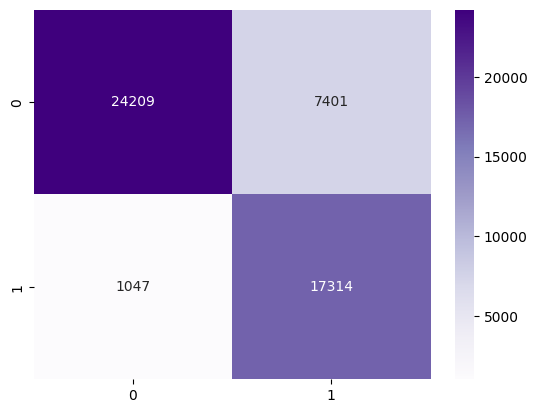

In [19]:
matriz_confusao_1 = confusion_matrix(y_teste, y_predicao_binaria_1)
sns.heatmap(matriz_confusao_1, annot=True, fmt='d', cmap='Purples')

##### 7.1.2. Relatório de Classificação
---

In [20]:
relatorio_classificacao_1 = classification_report(y_teste, y_predicao_binaria_1)
print(relatorio_classificacao_1)

              precision    recall  f1-score   support

         0.0       0.96      0.77      0.85     31610
         1.0       0.70      0.94      0.80     18361

    accuracy                           0.83     49971
   macro avg       0.83      0.85      0.83     49971
weighted avg       0.86      0.83      0.83     49971



##### 7.1.3. Curva ROC-AUC
---

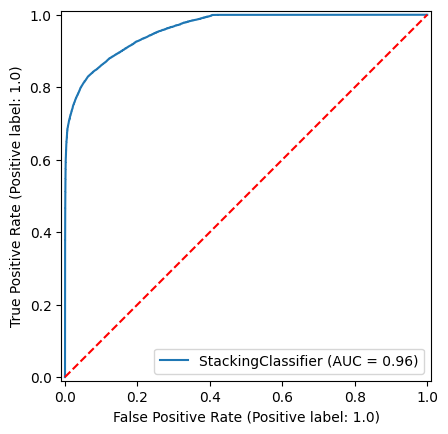

In [21]:
pg.gerar_roc_auc(stacking, X_teste, y_teste)

##### 7.1.4. Curva Precision-Recall
---

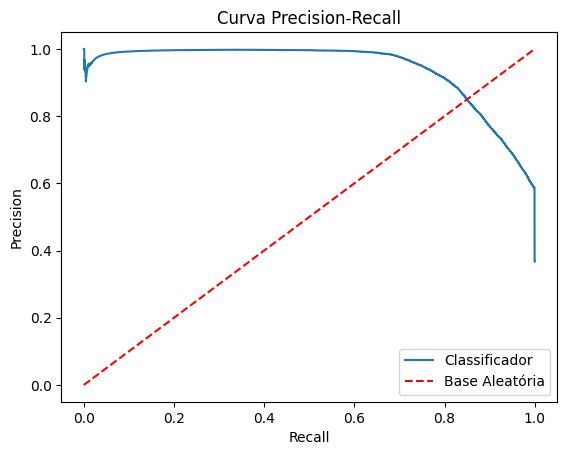

In [22]:
pg.gerar_curva_pr(y_teste, y_predicao_probabilistica_1)

In [23]:
pm.imprimir_prt(y_teste, y_predicao_probabilistica_1, obj_recall=True, meta_recall=0.95, obj_precision=True, meta_precision=0.95, obj_f1=True)


 - Objetivo focado em Recall (meta = 95.0%)
      Limiar ideal a ser usado: 0.4774
      Recall real obtido: 95.00% (Ataques detectados)
      Precision real obtida: 68.90% (Acerto dos alertas disparados)

 - Objetivo focado em Precision (meta >= 95.0%)
      Limiar ideal a ser usado: 0.8092
      Recall real obtido: 75.00% (Ataques detectados)
      Precision real obtida: 95.00% (Acerto dos alertas disparados)

 - Equilíbrio Simétrico (Max F1-Score)
      Limiar ideal: 0.7453
      Recall neste ponto: 82.83% (Ataques detectados)
      Precision neste ponto: 88.49% (Acerto dos alertas)


##### 7.1.5. Curva de Aprendizado
---

In [24]:
pg.gerar_curva_aprendizado(stacking)

O modelo StackingClassifier não possui o atributo 'loss_curve_'.


A curva não mostra `Underfitting`, pois não há um número de loss estagnado e sim, alterações que mostram o aprendizado do modelo, via retropropagação. Também não mostra `Overfitting`, pois a queda brusca de loss ocorre somente nas primeiras iterações, apó isso, ela vai se estabilizando. 

#### 7.2. Limiar Equilibrado
---

##### 7.2.1. Matriz de Confusão
---

Limiar de equilíbrio do F1-Score entre Recall e Precision:

In [25]:
_, limiar_stacking, _ = pm.extrair_f1(y_teste, y_predicao_probabilistica_1)
print(limiar_stacking)

0.7453494268460579


In [26]:
y_predicao_probabilistica_equilibrada_1 = (y_predicao_probabilistica_1 > limiar_stacking).astype(int)

<Axes: >

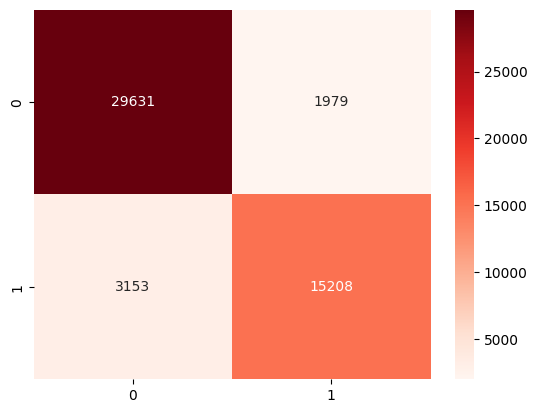

In [27]:
matriz_confusao_equilibrada_1 = confusion_matrix(y_teste, y_predicao_probabilistica_equilibrada_1)
sns.heatmap(matriz_confusao_equilibrada_1, annot=True, fmt='d', cmap='Reds')

##### 8.2.2. Relatório de Classificação
---

In [28]:
relatorio_classificacao_equilibrado_1 = classification_report(y_teste, y_predicao_probabilistica_equilibrada_1)
print(relatorio_classificacao_equilibrado_1)

              precision    recall  f1-score   support

         0.0       0.90      0.94      0.92     31610
         1.0       0.88      0.83      0.86     18361

    accuracy                           0.90     49971
   macro avg       0.89      0.88      0.89     49971
weighted avg       0.90      0.90      0.90     49971



## E) Desenvolvimento do Modelo de StackingClassifier Ensemble com RFE
---

### 1. Aplicação do Recursive Feature Elimination (RFE) para diminuição da dimensionalidade
---

#### 1.1. Instanciamento da classe RFE
---

O objetivo é a diminuição da dimensionalidade, e a escolha das 30 features mais relevantes.

In [29]:
xgb_estimador = XGBClassifier(random_state=42, eval_metric='logloss')

In [30]:
seletor_rfe = RFE(estimator=xgb_estimador, n_features_to_select=30)

#### 1.2. Aplicação do RFE em X_treino
---

In [31]:
X_treino_reduzido = seletor_rfe.fit_transform(X_treino, y_treino)

In [32]:
colunas_originais = X_treino.columns
print(f'Registros e features de treino ANTES da aplicação do RFE:\n - Número de features e registros: {X_treino.shape}\n - Nomes das features:\n{X_treino.columns}\n')
colunas_selecionadas = colunas_originais[seletor_rfe.support_]
print(f'\nRegistros e features de treino DEPOIS da aplicação do RFE:\n - Número de features e registros:  {X_treino_reduzido.shape} \n - Nomes das features:\n{list(colunas_selecionadas)}')

Registros e features de treino ANTES da aplicação do RFE:
 - Número de features e registros: (96822, 47)
 - Nomes das features:
Index(['duracao_conexao_seg', 'num_pacotes_origem', 'num_pacotes_destino',
       'total_bytes_origem', 'total_bytes_destino', 'taxa_pacote',
       'carga_origem', 'carga_destino', 'pacotes_perdidos_origem',
       'pacotes_perdidos_destino', 'tempo_medio_pacote_origem',
       'bytes_por_pacote_destino', 'var_lat_pacotes_origem',
       'var_lat_pacotes_destino', 'tamanho_janela_tcp_origem',
       'num_sequencia_tcp_origem', 'num_sequencia_tcp_destino',
       'tamanho_janela_tcp_destino', 'rtt_handshake_tcp', 'tempo_syn_synack',
       'tempo_synack_ack', 'tamanho_medio_pacotes_origem',
       'tamanho_medio_pacotes_destino', 'profundidade_transacao_http',
       'tamanho_corpo_resposta_http', 'conexoes_recentes_ip_porta_destino',
       'conexoes_recentes_ip_porta_origem', 'ftp_autenticada',
       'num_comandos_ftp', 'num_metodos_http',
       'ip_porta_

In [33]:
type(X_treino_reduzido)

numpy.ndarray

In [34]:
X_treino_reduzido_df = pd.DataFrame(X_treino_reduzido, columns=colunas_selecionadas)
X_treino_reduzido_df.head()

,num_pacotes_origem,total_bytes_origem,total_bytes_destino,carga_origem,carga_destino,pacotes_perdidos_origem,pacotes_perdidos_destino,tempo_medio_pacote_origem,var_lat_pacotes_origem,tamanho_janela_tcp_origem,...,protocolo_rede_udp,servico_conexao_-,servico_conexao_ftp,servico_conexao_ftp-data,servico_conexao_http,servico_conexao_outros,servico_conexao_smtp,estado_conexao_CON,estado_conexao_INT,estado_conexao_outros
0,-0.250,-0.329992,-0.154433,-0.034939,-0.002418,-0.4,-0.333333,-0.054359,-0.337678,1.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.250,-0.131161,12.130358,-0.044014,0.808271,0.0,2.500000,0.269346,-0.330958,1.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,-0.125,-0.285714,3.666471,-0.054756,0.083443,-0.2,0.666667,2.568450,3.349831,1.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.125,-0.175439,0.021139,-0.052917,-0.010829,-0.2,0.166667,1.570283,-0.288459,1.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.000,-0.214703,-0.126248,-0.043752,-0.009800,0.0,-0.166667,0.241995,0.175293,1.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [35]:
for feature in X_treino_reduzido_df.columns:
    print(f'\nFeature {feature.upper()}:')
    print(f'\n - Amplitude: de {X_treino_reduzido_df[feature].min()} a {X_treino_reduzido_df[feature].max()}')
    print(f'\n - Magnitude: {X_treino_reduzido_df[feature].max() - X_treino_reduzido_df[feature].min()}\n')


Feature NUM_PACOTES_ORIGEM:

 - Amplitude: de -0.5625 a 600.375

 - Magnitude: 600.9375


Feature TOTAL_BYTES_ORIGEM:

 - Amplitude: de -0.42606516290726815 a 5415.2819548872185

 - Magnitude: 5415.708020050126


Feature TOTAL_BYTES_DESTINO:

 - Amplitude: de -0.20493247210804463 a 4302.6576629477395

 - Magnitude: 4302.862595419848


Feature CARGA_ORIGEM:

 - Amplitude: de -0.057231631081325486 a 9427.744951992034

 - Magnitude: 9427.802183623115


Feature CARGA_DESTINO:

 - Amplitude: de -0.016328903360192524 a 36.700989512499405

 - Magnitude: 36.717318415859594


Feature PACOTES_PERDIDOS_ORIGEM:

 - Amplitude: de -0.4 a 960.2

 - Magnitude: 960.6


Feature PACOTES_PERDIDOS_DESTINO:

 - Amplitude: de -0.3333333333333333 a 913.6666666666666

 - Magnitude: 914.0


Feature TEMPO_MEDIO_PACOTE_ORIGEM:

 - Amplitude: de -0.36133865318408365 a 1065.6872198364367

 - Magnitude: 1066.0485584896207


Feature VAR_LAT_PACOTES_ORIGEM:

 - Amplitude: de -0.34416657687734703 a 313.6919244498777



#### 1.3. Aplicação do RFE em X_teste
---

In [36]:
X_teste_reduzido = seletor_rfe.transform(X_teste)

In [37]:
colunas_originais = X_teste.columns
print(f'Registros e features de treino ANTES da aplicação do PCA:\n - Número de features e registros: {X_teste.shape}\n - Nomes das features: {X_teste.columns}\n')
colunas_selecionadas = colunas_originais[seletor_rfe.support_]
print(f'\nRegistros e features de treino DEPOIS da aplicação do PCA:\n - Número de features e registros:  {X_teste_reduzido.shape} \n - Nomes das features: {list(colunas_selecionadas)}')

Registros e features de treino ANTES da aplicação do PCA:
 - Número de features e registros: (49971, 47)
 - Nomes das features: Index(['duracao_conexao_seg', 'num_pacotes_origem', 'num_pacotes_destino',
       'total_bytes_origem', 'total_bytes_destino', 'taxa_pacote',
       'carga_origem', 'carga_destino', 'pacotes_perdidos_origem',
       'pacotes_perdidos_destino', 'tempo_medio_pacote_origem',
       'bytes_por_pacote_destino', 'var_lat_pacotes_origem',
       'var_lat_pacotes_destino', 'tamanho_janela_tcp_origem',
       'num_sequencia_tcp_origem', 'num_sequencia_tcp_destino',
       'tamanho_janela_tcp_destino', 'rtt_handshake_tcp', 'tempo_syn_synack',
       'tempo_synack_ack', 'tamanho_medio_pacotes_origem',
       'tamanho_medio_pacotes_destino', 'profundidade_transacao_http',
       'tamanho_corpo_resposta_http', 'conexoes_recentes_ip_porta_destino',
       'conexoes_recentes_ip_porta_origem', 'ftp_autenticada',
       'num_comandos_ftp', 'num_metodos_http',
       'ip_porta_

In [38]:
type(X_teste_reduzido)

numpy.ndarray

In [39]:
X_teste_reduzido_df = pd.DataFrame(X_teste_reduzido, columns=colunas_selecionadas)
X_teste_reduzido_df.head()

,num_pacotes_origem,total_bytes_origem,total_bytes_destino,carga_origem,carga_destino,pacotes_perdidos_origem,pacotes_perdidos_destino,tempo_medio_pacote_origem,var_lat_pacotes_origem,tamanho_janela_tcp_origem,...,protocolo_rede_udp,servico_conexao_-,servico_conexao_ftp,servico_conexao_ftp-data,servico_conexao_http,servico_conexao_outros,servico_conexao_smtp,estado_conexao_CON,estado_conexao_INT,estado_conexao_outros
0,-0.5,-0.230576,-0.204932,283.916144,-0.016329,-0.4,-0.333333,-0.361200,-0.344167,0.0,...,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,-0.5,0.298246,-0.204932,1387.032509,-0.016329,-0.4,-0.333333,-0.361238,-0.344167,0.0,...,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,-0.5,0.008354,-0.204932,1345.152161,-0.016329,-0.4,-0.333333,-0.361275,-0.344167,0.0,...,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,-0.5,-0.061821,-0.204932,944.612285,-0.016329,-0.4,-0.333333,-0.361263,-0.344167,0.0,...,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,-0.5,0.450292,-0.204932,1338.854364,-0.016329,-0.4,-0.333333,-0.361212,-0.344167,0.0,...,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [40]:
for feature in X_teste_reduzido_df.columns:
    print(f'\nFeature {feature.upper()}:')
    print(f'\n - Amplitude: de {X_teste_reduzido_df[feature].min()} a {X_teste_reduzido_df[feature].max()}')
    print(f'\n - Magnitude: {X_teste_reduzido_df[feature].max() - X_teste_reduzido_df[feature].min()}\n')


Feature NUM_PACOTES_ORIGEM:

 - Amplitude: de -0.5625 a 664.75

 - Magnitude: 665.3125


Feature TOTAL_BYTES_ORIGEM:

 - Amplitude: de -0.4277360066833751 a 5996.126148705096

 - Magnitude: 5996.55388471178


Feature TOTAL_BYTES_DESTINO:

 - Amplitude: de -0.20493247210804463 a 4303.239283617147

 - Magnitude: 4303.444216089255


Feature CARGA_ORIGEM:

 - Amplitude: de -0.057231631081325486 a 8294.141531483323

 - Magnitude: 8294.198763114404


Feature CARGA_DESTINO:

 - Amplitude: de -0.016328903360192524 a 34.078326484587734

 - Magnitude: 34.094655387947924


Feature PACOTES_PERDIDOS_ORIGEM:

 - Amplitude: de -0.4 a 1063.4

 - Magnitude: 1063.8000000000002


Feature PACOTES_PERDIDOS_DESTINO:

 - Amplitude: de -0.3333333333333333 a 917.5

 - Magnitude: 917.8333333333334


Feature TEMPO_MEDIO_PACOTE_ORIGEM:

 - Amplitude: de -0.36133865318408365 a 757.8754070510212

 - Magnitude: 758.2367457042053


Feature VAR_LAT_PACOTES_ORIGEM:

 - Amplitude: de -0.34416657687734703 a 318.71288845

### 2. Criação dos modelos campeões de XGBoost, MLP de duas camados ocultas e Regressão Logística com RFE
---

#### 2.1. Regressão Logística
---

In [41]:
rl_rfe = joblib.load('../persistencia/modelos_persistentes/regressao_logistica/rl_c_rfe.pkl')

#### 2.2. XGBoost
---

In [42]:
xgb_rfe = joblib.load('../persistencia/modelos_persistentes/xgboost/xgboost_c_rfe.pkl')

#### 2.3. MLP
---

In [43]:
mlp_rfe = joblib.load('../persistencia/modelos_persistentes/mlp/mlp_3c/mlp_3c_rfe.pkl')

### 3. Predições Probabilísticas dos modelos criados
---

In [44]:
y_pred_rl_rfe = pm.imprimir_desempenho(rl_rfe.predict_proba, X_teste_reduzido_df)[:,1]


RELATÓRIO DE DESEMPENHO DE PROCESSAMENTO:

  Execução iniciada em: 02/06/2026 08:55:16

    1. TEMPO: 0.0142s (0.00 min)

    2. MEMÓRIA RAM (Processo Atual):
        - Pico de processamento: 1.53 MB
        - Diferença líquida de RAM no processo: 1.52 MB
        - Total RAM alocada para o processo: 487.57 MB

    3. CPU:
        - Uso de CPU do sistema durante a execução: 25.0%

  Execução concluída em: 02/06/2026 08:55:16



In [45]:
y_pred_xgb_rfe = pm.imprimir_desempenho(xgb_rfe.predict_proba, X_teste_reduzido_df)[:,1]


RELATÓRIO DE DESEMPENHO DE PROCESSAMENTO:

  Execução iniciada em: 02/06/2026 08:55:16

    1. TEMPO: 0.0535s (0.00 min)

    2. MEMÓRIA RAM (Processo Atual):
        - Pico de processamento: 0.80 MB
        - Diferença líquida de RAM no processo: 0.59 MB
        - Total RAM alocada para o processo: 488.17 MB

    3. CPU:
        - Uso de CPU do sistema durante a execução: 36.1%

  Execução concluída em: 02/06/2026 08:55:16



In [46]:
y_pred_mlp_rfe = pm.imprimir_desempenho(mlp_rfe.predict_proba, X_teste_reduzido_df)[:,1]


RELATÓRIO DE DESEMPENHO DE PROCESSAMENTO:

  Execução iniciada em: 02/06/2026 08:55:16

    1. TEMPO: 0.6638s (0.01 min)

    2. MEMÓRIA RAM (Processo Atual):
        - Pico de processamento: 48.80 MB
        - Diferença líquida de RAM no processo: 1.15 MB
        - Total RAM alocada para o processo: 489.32 MB

    3. CPU:
        - Uso de CPU do sistema durante a execução: 59.4%

  Execução concluída em: 02/06/2026 08:55:16



### 4. Junção dos estimadores
---

In [47]:
estimadores_rfe = [
    ('XGBoost_rfe', xgb_rfe),
    ('MLP_rfe', mlp_rfe)
] 

### 5. Criação do Modelo StackingClassifier

In [48]:
stacking_rfe = StackingClassifier(estimators=estimadores_rfe, final_estimator=rl_rfe, cv=2)

### 6. Treino do modelo
---

In [49]:
pm.imprimir_desempenho(stacking_rfe.fit, X_treino_reduzido_df, y_treino)

Iteration 1, loss = 0.40010779
Iteration 2, loss = 0.27792251
Iteration 3, loss = 0.24135449
Iteration 4, loss = 0.23187298
Iteration 5, loss = 0.22244945
Iteration 6, loss = 0.21438187
Iteration 7, loss = 0.20856697
Iteration 8, loss = 0.20579703
Iteration 9, loss = 0.20216051
Iteration 10, loss = 0.19507828
Iteration 11, loss = 0.19337043
Iteration 12, loss = 0.19234485
Iteration 13, loss = 0.19086663
Iteration 14, loss = 0.19052183
Iteration 15, loss = 0.18840481
Iteration 16, loss = 0.18629696
Iteration 17, loss = 0.18842875
Iteration 18, loss = 0.18915340
Iteration 19, loss = 0.18525021
Iteration 20, loss = 0.18642216
Iteration 21, loss = 0.18557640
Iteration 22, loss = 0.18472948
Iteration 23, loss = 0.18520721
Iteration 24, loss = 0.18348902
Iteration 25, loss = 0.18303190
Iteration 26, loss = 0.18181327
Iteration 27, loss = 0.18382444
Iteration 28, loss = 0.18142125
Iteration 29, loss = 0.18087289
Iteration 30, loss = 0.18138573
Iteration 31, loss = 0.18227945
Iteration 32, los

StackingClassifier(cv=2,
                   estimators=[('XGBoost_rfe',
                                XGBClassifier(base_score=None, booster=None,
                                              callbacks=None,
                                              colsample_bylevel=None,
                                              colsample_bynode=None,
                                              colsample_bytree=None,
                                              device=None,
                                              early_stopping_rounds=None,
                                              enable_categorical=False,
                                              eval_metric='auc',
                                              feature_types=None, gamma=None,
                                              grow_policy=None,
                                              importance_type=None,
                                              interaction_constraints=...
                                              num_parallel_tree=None,
                                              random_state=42, ...)),
                               ('MLP_rfe',
                                MLPClassifier(alpha=0.001,
                                              hidden_layer_sizes=(64, 64, 64),
                                              learning_rate='adaptive',
                                              learning_rate_init=0.0005,
                                              max_iter=2000,
                                              n_iter_no_change=15,
                                              random_state=42, verbose=True))],
                   final_estimator=LogisticRegression(class_weight='balanced',
                                                      l1_ratio=0.8,
                                                      max_iter=5000,
                                                      penalty='elasticnet',
                                                      random_state=42,
                                                      solver='saga'))

### 7. Realização das Predições de Teste
---

#### 7.1. Predição Probababilística
---

In [50]:
y_predicao_probabilistica_2 = pm.imprimir_desempenho(stacking_rfe.predict_proba, X_teste_reduzido_df)[:, 1]


RELATÓRIO DE DESEMPENHO DE PROCESSAMENTO:

  Execução iniciada em: 02/06/2026 09:31:35

    1. TEMPO: 0.7013s (0.01 min)

    2. MEMÓRIA RAM (Processo Atual):
        - Pico de processamento: 49.20 MB
        - Diferença líquida de RAM no processo: 4.24 MB
        - Total RAM alocada para o processo: 498.17 MB

    3. CPU:
        - Uso de CPU do sistema durante a execução: 70.0%

  Execução concluída em: 02/06/2026 09:31:35



#### 7.2. Predição Binária
---

In [51]:
y_predicao_binaria_2 = pm.imprimir_desempenho(stacking_rfe.predict, X_teste_reduzido_df)


RELATÓRIO DE DESEMPENHO DE PROCESSAMENTO:

  Execução iniciada em: 02/06/2026 09:31:35

    1. TEMPO: 0.6106s (0.01 min)

    2. MEMÓRIA RAM (Processo Atual):
        - Pico de processamento: 49.19 MB
        - Diferença líquida de RAM no processo: 0.82 MB
        - Total RAM alocada para o processo: 498.99 MB

    3. CPU:
        - Uso de CPU do sistema durante a execução: 59.2%

  Execução concluída em: 02/06/2026 09:31:36



### 8. Desempenho do modelo
---

#### 8.1. Limiar Padrão (0.5)
---

##### 8.1.1. Matriz de Confusão
---

<Axes: >

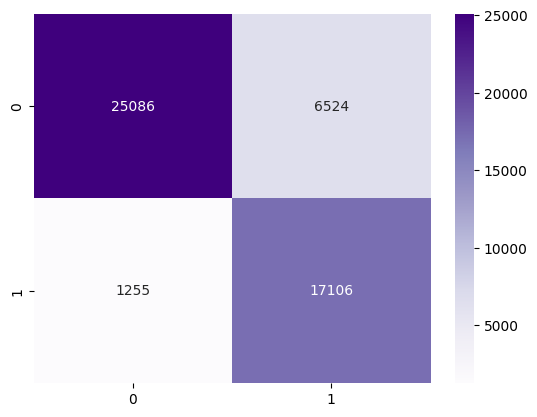

In [52]:
matriz_confusao_2 = confusion_matrix(y_teste, y_predicao_binaria_2)
sns.heatmap(matriz_confusao_2, annot=True, fmt='d', cmap='Purples')

##### 8.1.2. Relatório de Classificação
---

In [53]:
relatorio_classificacao_2 = classification_report(y_teste, y_predicao_binaria_2)
print(relatorio_classificacao_2)

              precision    recall  f1-score   support

         0.0       0.95      0.79      0.87     31610
         1.0       0.72      0.93      0.81     18361

    accuracy                           0.84     49971
   macro avg       0.84      0.86      0.84     49971
weighted avg       0.87      0.84      0.85     49971



##### 8.1.3. Curva ROC-AUC
---

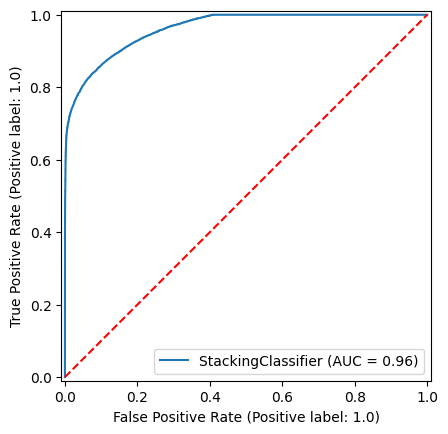

In [54]:
pg.gerar_roc_auc(stacking_rfe, X_teste_reduzido_df, y_teste)

##### 8.1.4. Curva Precision-Recall
---

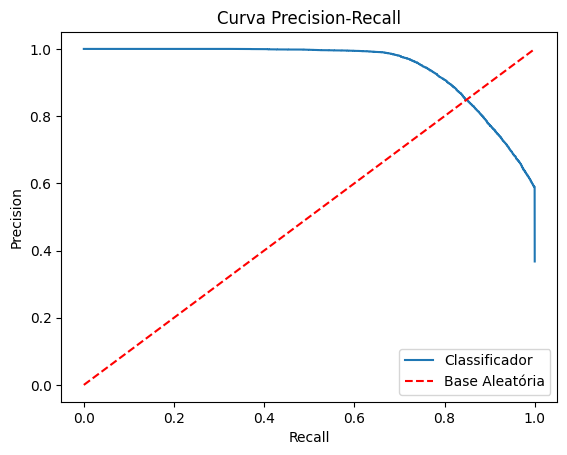

In [55]:
pg.gerar_curva_pr(y_teste, y_predicao_probabilistica_2)

In [56]:
pm.imprimir_prt(y_teste, y_predicao_probabilistica_2, obj_recall=True, meta_recall=0.95, obj_precision=True, meta_precision=0.95, obj_f1=True)


 - Objetivo focado em Recall (meta = 95.0%)
      Limiar ideal a ser usado: 0.4445
      Recall real obtido: 95.00% (Ataques detectados)
      Precision real obtida: 69.15% (Acerto dos alertas disparados)

 - Objetivo focado em Precision (meta >= 95.0%)
      Limiar ideal a ser usado: 0.7997
      Recall real obtido: 75.07% (Ataques detectados)
      Precision real obtida: 95.00% (Acerto dos alertas disparados)

 - Equilíbrio Simétrico (Max F1-Score)
      Limiar ideal: 0.7310
      Recall neste ponto: 82.47% (Ataques detectados)
      Precision neste ponto: 88.22% (Acerto dos alertas)


##### 8.1.5. Curva de Aprendizado
---

In [57]:
pg.gerar_curva_aprendizado(stacking_rfe)

O modelo StackingClassifier não possui o atributo 'loss_curve_'.


A curva não mostra `Underfitting`, pois não há um número de loss estagnado e sim, alterações que mostram o aprendizado do modelo, via retropropagação. Também não mostra `Overfitting`, pois a queda brusca de loss ocorre somente nas primeiras iterações, apó isso, ela vai se estabilizando. 

#### 8.2. Limiar Equilibrado
---

##### 8.2.1. Matriz de Confusão
---

Limiar de equilíbrio do F1-Score entre Recall e Precision:

In [58]:
_, limiar_stacking_rfe, _ = pm.extrair_f1(y_teste, y_predicao_probabilistica_2)
print(limiar_stacking_rfe)

0.7310263196217649


In [59]:
y_predicao_probabilistica_equilibrada_2 = (y_predicao_probabilistica_2 > limiar_stacking_rfe).astype(int)

<Axes: >

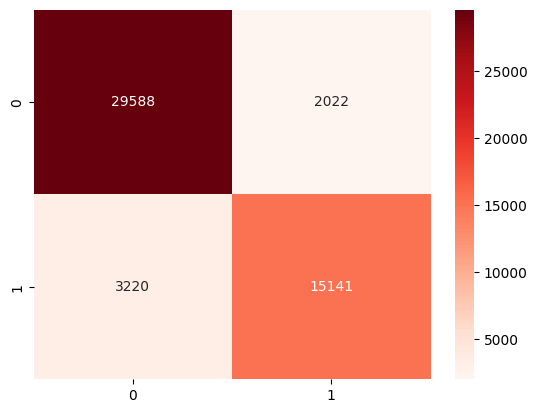

In [60]:
matriz_confusao_equilibrada_2 = confusion_matrix(y_teste, y_predicao_probabilistica_equilibrada_2)
sns.heatmap(matriz_confusao_equilibrada_2, annot=True, fmt='d', cmap='Reds')

##### 8.2.2. Relatório de Classificação
---

In [61]:
relatorio_classificacao_equilibrado_2 = classification_report(y_teste, y_predicao_probabilistica_equilibrada_2)
print(relatorio_classificacao_equilibrado_2)

              precision    recall  f1-score   support

         0.0       0.90      0.94      0.92     31610
         1.0       0.88      0.82      0.85     18361

    accuracy                           0.90     49971
   macro avg       0.89      0.88      0.89     49971
weighted avg       0.89      0.90      0.89     49971



## F) Comparando os Modelos
---

#### 1. Dados de Desempenho Modelo
---

In [62]:
print('\nComparação entre os modelos campeões a partir de Precision, Recall e F1-Score das Classes 0 e 1:\n')

print('\n1. MODELO CAMPEÃO SEM RFE:')
print('\n - Padrão:\n')
pm.imprimir_desempenho_modelo(matriz_confusao_1)
print('\n - Equilibrado:\n')
pm.imprimir_desempenho_modelo(matriz_confusao_equilibrada_1)

print('\n\n2. MODELO CAMPEÃO COM RFE:')
print('\n - Padrão:\n')
pm.imprimir_desempenho_modelo(matriz_confusao_2)
print('\n - Equilibrado:\n')
pm.imprimir_desempenho_modelo(matriz_confusao_equilibrada_2)



Comparação entre os modelos campeões a partir de Precision, Recall e F1-Score das Classes 0 e 1:


1. MODELO CAMPEÃO SEM RFE:

 - Padrão:

O total de predições de teste foi 49971.


 -> Classe 0:
    - Verdadeiro Negativo (TN): há 24209 casos, o que representa, aproximadamente, 48.45% do total de predições de teste.
    - Falso Negativo (FN): há 1047 casos, o que representa, aproximadamente, 2.10% do total de predições de teste.

 -> Classe 1:
   - Verdadeiro Positivo (TP): há 17314 casos, o que representa, aproximadamente, 34.65% do total de predições de teste.
   - Falso Positivo (FP): há 7401 casos, o que representa, aproximadamente, 14.81% do total de predições de teste.


 -> Resultados Gerais:
    - A Acurácia total do modelo se dá por: (tp + tn) / total. Seu valor é 0.8309.
    - A quantidade de vezes que o modelo acertou é expressa por TN + TP e é igual a 41523, de um total de 49971. Corresponde a, aproximadamente, 83.09% das predições.
    - A quantidade de vezes que o modelo

#### 2. Diferenças entre os desempenhos
---

In [63]:
# Modelo sem RFE
dados_modelo_1 = pm.extracao_desempenho_modelo(matriz_confusao_1)
dados_modelo_equilibrado_1 = pm.extracao_desempenho_modelo(matriz_confusao_equilibrada_1)

# Modelo com RFE
dados_modelo_2 = pm.extracao_desempenho_modelo(matriz_confusao_2)
dados_modelo_equilibrado_2 = pm.extracao_desempenho_modelo(matriz_confusao_equilibrada_2)

# Total de registros
total_registros = dados_modelo_1['tn'] + dados_modelo_1['tp'] + dados_modelo_1['fn'] + dados_modelo_1['fp']

In [64]:
print('A) As diferenças métricas entre os modelos são:\n')
print('Nota: Valores de diferença ou percentual positivos indicam que o primeiro modelo/limiar apresenta resultados maiores que o segundo. Valores negativos indicam o oposto (o segundo termo possui valores maiores).')

print('\n1. Limiar Padrão:')
print('\n - Métricas Básicas:')
print(f'    TN: Sem RFE - {dados_modelo_1["tn"]} | Com RFE - {dados_modelo_2["tn"]} -> Diferença de {dados_modelo_1["tn"] - dados_modelo_2["tn"]} ou {pm.calcular_percentual((dados_modelo_1["tn"] - dados_modelo_2["tn"]), total_registros):.2f}%')
print(f'    TP: Sem RFE - {dados_modelo_1["tp"]} | Com RFE - {dados_modelo_2["tp"]} -> Diferença de {dados_modelo_1["tp"] - dados_modelo_2["tp"]} ou {pm.calcular_percentual((dados_modelo_1["tp"] - dados_modelo_2["tp"]), total_registros):.2f}%')
print(f'    FN: Sem RFE - {dados_modelo_1["fn"]} | Com RFE - {dados_modelo_2["fn"]} -> Diferença de {dados_modelo_1["fn"] - dados_modelo_2["fn"]} ou {pm.calcular_percentual((dados_modelo_1["fn"] - dados_modelo_2["fn"]), total_registros):.2f}%')
print(f'    FP: Sem RFE - {dados_modelo_1["fp"]} | Com RFE - {dados_modelo_2["fp"]} -> Diferença de {dados_modelo_1["fp"] - dados_modelo_2["fp"]} ou {pm.calcular_percentual((dados_modelo_1["fp"] - dados_modelo_2["fp"]), total_registros):.2f}%')

print('\n - Acurácia Geral do Modelo:')
print(f'    Acurácia: Sem RFE - {dados_modelo_1["accuracy"]} | Com RFE - {dados_modelo_2["accuracy"]} -> Diferença de {round(dados_modelo_1["accuracy"] - dados_modelo_2["accuracy"], 4)} ou {pm.calcular_percentual(dados_modelo_1["accuracy"] - dados_modelo_2["accuracy"], 1):.2f}%')

print('\n - Métricas por Classe:')
print(f'    Recall (0): Sem RFE - {dados_modelo_1["classe_0"]["recall"]} | Com RFE - {dados_modelo_2["classe_0"]["recall"]} -> Diferença de {round(dados_modelo_1["classe_0"]["recall"] - dados_modelo_2["classe_0"]["recall"], 4)} ou {pm.calcular_percentual(dados_modelo_1["classe_0"]["recall"] - dados_modelo_2["classe_0"]["recall"], 1):.2f}%')
print(f'    Recall(1): Sem RFE - {dados_modelo_1["classe_1"]["recall"]} | Com RFE - {dados_modelo_2["classe_1"]["recall"]} -> Diferença de {round(dados_modelo_1["classe_1"]["recall"] - dados_modelo_2["classe_1"]["recall"], 4)} ou {pm.calcular_percentual(dados_modelo_1["classe_1"]["recall"] - dados_modelo_2["classe_1"]["recall"], 1):.2f}%')
print(f'\n    Precision(0): Sem RFE - {dados_modelo_1["classe_0"]["precision"]} | Com RFE - {dados_modelo_2["classe_0"]["precision"]} -> Diferença de {round(dados_modelo_1["classe_0"]["precision"] - dados_modelo_2["classe_0"]["precision"], 4)} ou {pm.calcular_percentual(dados_modelo_1["classe_0"]["precision"] - dados_modelo_2["classe_0"]["precision"], 1):.2f}%')
print(f'    Precision(1): Sem RFE - {dados_modelo_1["classe_1"]["precision"]} | Com RFE - {dados_modelo_2["classe_1"]["precision"]} -> Diferença de {round(dados_modelo_1["classe_1"]["precision"] - dados_modelo_2["classe_1"]["precision"], 4)} ou {pm.calcular_percentual(dados_modelo_1["classe_1"]["precision"] - dados_modelo_2["classe_1"]["precision"], 1):.2f}%')
print(f'\n    F1-Score(0): Sem RFE - {dados_modelo_1["classe_0"]["f1_score"]} | Com RFE - {dados_modelo_2["classe_0"]["f1_score"]} -> Diferença de {round(dados_modelo_1["classe_0"]["f1_score"] - dados_modelo_2["classe_0"]["f1_score"], 4)} ou {pm.calcular_percentual(dados_modelo_1["classe_0"]["f1_score"] - dados_modelo_2["classe_0"]["f1_score"], 1):.2f}%')
print(f'    F1-Score(1): Sem RFE - {dados_modelo_1["classe_1"]["f1_score"]} | Com RFE - {dados_modelo_2["classe_1"]["f1_score"]} -> Diferença de {round(dados_modelo_1["classe_1"]["f1_score"] - dados_modelo_2["classe_1"]["f1_score"], 4)} ou {pm.calcular_percentual(dados_modelo_1["classe_1"]["f1_score"] - dados_modelo_2["classe_1"]["f1_score"], 1):.2f}%')

print('\n2. Limiar Equilibrado:')
print('\n - Métricas Básicas:')
print(f'    TN: Sem RFE - {dados_modelo_equilibrado_1["tn"]} | Com RFE - {dados_modelo_equilibrado_2["tn"]} -> Diferença de {dados_modelo_equilibrado_1["tn"] - dados_modelo_equilibrado_2["tn"]} ou {pm.calcular_percentual((dados_modelo_equilibrado_1["tn"] - dados_modelo_equilibrado_2["tn"]), total_registros):.2f}%')
print(f'    TP: Sem RFE - {dados_modelo_equilibrado_1["tp"]} | Com RFE - {dados_modelo_equilibrado_2["tp"]} -> Diferença de {dados_modelo_equilibrado_1["tp"] - dados_modelo_equilibrado_2["tp"]} ou {pm.calcular_percentual((dados_modelo_equilibrado_1["tp"] - dados_modelo_equilibrado_2["tp"]), total_registros):.2f}%')
print(f'    FN: Sem RFE - {dados_modelo_equilibrado_1["fn"]} | Com RFE - {dados_modelo_equilibrado_2["fn"]} -> Diferença de {dados_modelo_equilibrado_1["fn"] - dados_modelo_equilibrado_2["fn"]} ou {pm.calcular_percentual((dados_modelo_equilibrado_1["fn"] - dados_modelo_equilibrado_2["fn"]), total_registros):.2f}%')
print(f'    FP: Sem RFE - {dados_modelo_equilibrado_1["fp"]} | Com RFE - {dados_modelo_equilibrado_2["fp"]} -> Diferença de {dados_modelo_equilibrado_1["fp"] - dados_modelo_equilibrado_2["fp"]} ou {pm.calcular_percentual((dados_modelo_equilibrado_1["fp"] - dados_modelo_equilibrado_2["fp"]), total_registros):.2f}%')

print('\n - Acurácia Geral do Modelo:')
print(f'    Acurácia: Sem RFE - {dados_modelo_equilibrado_1["accuracy"]} | Com RFE - {dados_modelo_equilibrado_2["accuracy"]} -> Diferença de {round(dados_modelo_equilibrado_1["accuracy"] - dados_modelo_equilibrado_2["accuracy"], 4)} ou {pm.calcular_percentual(dados_modelo_equilibrado_1["accuracy"] - dados_modelo_equilibrado_2["accuracy"], 1):.2f}%')

print('\n - Métricas por Classe:')
print(f'    Recall (0): Sem RFE - {dados_modelo_equilibrado_1["classe_0"]["recall"]} | Com RFE - {dados_modelo_equilibrado_2["classe_0"]["recall"]} -> Diferença de {round(dados_modelo_equilibrado_1["classe_0"]["recall"] - dados_modelo_equilibrado_2["classe_0"]["recall"], 4)} ou {pm.calcular_percentual(dados_modelo_equilibrado_1["classe_0"]["recall"] - dados_modelo_equilibrado_2["classe_0"]["recall"], 1):.2f}%')
print(f'    Recall (1): Sem RFE - {dados_modelo_equilibrado_1["classe_1"]["recall"]} | Com RFE - {dados_modelo_equilibrado_2["classe_1"]["recall"]} -> Diferença de {round(dados_modelo_equilibrado_1["classe_1"]["recall"] - dados_modelo_equilibrado_2["classe_1"]["recall"], 4)} ou {pm.calcular_percentual(dados_modelo_equilibrado_1["classe_1"]["recall"] - dados_modelo_equilibrado_2["classe_1"]["recall"], 1):.2f}%')
print(f'\n    Precision (0): Sem RFE - {dados_modelo_equilibrado_1["classe_0"]["precision"]} | Com RFE - {dados_modelo_equilibrado_2["classe_0"]["precision"]} -> Diferença de {round(dados_modelo_equilibrado_1["classe_0"]["precision"] - dados_modelo_equilibrado_2["classe_0"]["precision"], 4)} ou {pm.calcular_percentual(dados_modelo_equilibrado_1["classe_0"]["precision"] - dados_modelo_equilibrado_2["classe_0"]["precision"], 1):.2f}%')
print(f'    Precision (1): Sem RFE - {dados_modelo_equilibrado_1["classe_1"]["precision"]} | Com RFE - {dados_modelo_equilibrado_2["classe_1"]["precision"]} -> Diferença de {round(dados_modelo_equilibrado_1["classe_1"]["precision"] - dados_modelo_equilibrado_2["classe_1"]["precision"], 4)} ou {pm.calcular_percentual(dados_modelo_equilibrado_1["classe_1"]["precision"] - dados_modelo_equilibrado_2["classe_1"]["precision"], 1):.2f}%')
print(f'\n    F1-Score (0): Sem RFE - {dados_modelo_equilibrado_1["classe_0"]["f1_score"]} | Com RFE - {dados_modelo_equilibrado_2["classe_0"]["f1_score"]} -> Diferença de {round(dados_modelo_equilibrado_1["classe_0"]["f1_score"] - dados_modelo_equilibrado_2["classe_0"]["f1_score"], 4)} ou {pm.calcular_percentual(dados_modelo_equilibrado_1["classe_0"]["f1_score"] - dados_modelo_equilibrado_2["classe_0"]["f1_score"], 1):.2f}%')
print(f'    F1-Score (1): Sem RFE - {dados_modelo_equilibrado_1["classe_1"]["f1_score"]} | Com RFE - {dados_modelo_equilibrado_2["classe_1"]["f1_score"]} -> Diferença de {round(dados_modelo_equilibrado_1["classe_1"]["f1_score"] - dados_modelo_equilibrado_2["classe_1"]["f1_score"], 4)} ou {pm.calcular_percentual(dados_modelo_equilibrado_1["classe_1"]["f1_score"] - dados_modelo_equilibrado_2["classe_1"]["f1_score"], 1):.2f}%')

print('\n')
print('-'*220)
print('\n')

print('\nB) As diferenças métricas entre os limiares dos modelos são:\n')
print('\n1. Modelo sem RFE:')
print('\n - Métricas Básicas:')
print(f'    TN: Padrão - {dados_modelo_1["tn"]} | Equilibrado - {dados_modelo_equilibrado_1["tn"]} -> Diferença de {dados_modelo_1["tn"] - dados_modelo_equilibrado_1["tn"]} ou {pm.calcular_percentual((dados_modelo_1["tn"] - dados_modelo_equilibrado_1["tn"]), total_registros):.2f}%')
print(f'    TP: Padrão - {dados_modelo_1["tp"]} | Equilibrado - {dados_modelo_equilibrado_1["tp"]} -> Diferença de {dados_modelo_1["tp"] - dados_modelo_equilibrado_1["tp"]} ou {pm.calcular_percentual((dados_modelo_1["tp"] - dados_modelo_equilibrado_1["tp"]), total_registros):.2f}%')
print(f'    FN: Padrão - {dados_modelo_1["fn"]} | Equilibrado - {dados_modelo_equilibrado_1["fn"]} -> Diferença de {dados_modelo_1["fn"] - dados_modelo_equilibrado_1["fn"]} ou {pm.calcular_percentual((dados_modelo_1["fn"] - dados_modelo_equilibrado_1["fn"]), total_registros):.2f}%')
print(f'    FP: Padrão - {dados_modelo_1["fp"]} | Equilibrado - {dados_modelo_equilibrado_1["fp"]} -> Diferença de {dados_modelo_1["fp"] - dados_modelo_equilibrado_1["fp"]} ou {pm.calcular_percentual((dados_modelo_1["fp"] - dados_modelo_equilibrado_1["fp"]), total_registros):.2f}%')

print('\n - Acurácia Geral do Modelo:')
print(f'    Acurácia: Padrão - {dados_modelo_1["accuracy"]} | Equilibrado - {dados_modelo_equilibrado_1["accuracy"]} -> Diferença de {round(dados_modelo_1["accuracy"] - dados_modelo_equilibrado_1["accuracy"], 4)} ou {pm.calcular_percentual(dados_modelo_1["accuracy"] - dados_modelo_equilibrado_1["accuracy"], 1):.2f}%')

print('\n - Métricas por Classe:')
print(f'    Recall (0): Padrão - {dados_modelo_1["classe_0"]["recall"]} | Equilibrado - {dados_modelo_equilibrado_1["classe_0"]["recall"]} -> Diferença de {round(dados_modelo_1["classe_0"]["recall"] - dados_modelo_equilibrado_1["classe_0"]["recall"], 4)} ou {pm.calcular_percentual(dados_modelo_1["classe_0"]["recall"] - dados_modelo_equilibrado_1["classe_0"]["recall"], 1):.2f}%')
print(f'    Recall (1): Padrão - {dados_modelo_1["classe_1"]["recall"]} | Equilibrado - {dados_modelo_equilibrado_1["classe_1"]["recall"]} -> Diferença de {round(dados_modelo_1["classe_1"]["recall"] - dados_modelo_equilibrado_1["classe_1"]["recall"], 4)} ou {pm.calcular_percentual(dados_modelo_1["classe_1"]["recall"] - dados_modelo_equilibrado_1["classe_1"]["recall"], 1):.2f}%')
print(f'\n    Precision (0): Padrão - {dados_modelo_1["classe_0"]["precision"]} | Equilibrado - {dados_modelo_equilibrado_1["classe_0"]["precision"]} -> Diferença de {round(dados_modelo_1["classe_0"]["precision"] - dados_modelo_equilibrado_1["classe_0"]["precision"], 4)} ou {pm.calcular_percentual(dados_modelo_1["classe_0"]["precision"] - dados_modelo_equilibrado_1["classe_0"]["precision"], 1):.2f}%')
print(f'    Precision (1): Padrão - {dados_modelo_1["classe_1"]["precision"]} | Equilibrado - {dados_modelo_equilibrado_1["classe_1"]["precision"]} -> Diferença de {round(dados_modelo_1["classe_1"]["precision"] - dados_modelo_equilibrado_1["classe_1"]["precision"], 4)} ou {pm.calcular_percentual(dados_modelo_1["classe_1"]["precision"] - dados_modelo_equilibrado_1["classe_1"]["precision"], 1):.2f}%')
print(f'\n    F1-Score (0): Padrão - {dados_modelo_1["classe_0"]["f1_score"]} | Equilibrado - {dados_modelo_equilibrado_1["classe_0"]["f1_score"]} -> Diferença de {round(dados_modelo_1["classe_0"]["f1_score"] - dados_modelo_equilibrado_1["classe_0"]["f1_score"], 4)} ou {pm.calcular_percentual(dados_modelo_1["classe_0"]["f1_score"] - dados_modelo_equilibrado_1["classe_0"]["f1_score"], 1):.2f}%')
print(f'    F1-Score (1): Padrão - {dados_modelo_1["classe_1"]["f1_score"]} | Equilibrado - {dados_modelo_equilibrado_1["classe_1"]["f1_score"]} -> Diferença de {round(dados_modelo_1["classe_1"]["f1_score"] - dados_modelo_equilibrado_1["classe_1"]["f1_score"], 4)} ou {pm.calcular_percentual(dados_modelo_1["classe_1"]["f1_score"] - dados_modelo_equilibrado_1["classe_1"]["f1_score"], 1):.2f}%')

print('\n2. Modelo com RFE:')
print('\n - Métricas Básicas:')
print(f'    TN: Padrão - {dados_modelo_2["tn"]} | Equilibrado - {dados_modelo_equilibrado_2["tn"]} -> Diferença de {dados_modelo_2["tn"] - dados_modelo_equilibrado_2["tn"]} ou {pm.calcular_percentual((dados_modelo_2["tn"] - dados_modelo_equilibrado_2["tn"]), total_registros):.2f}%')
print(f'    TP: Padrão - {dados_modelo_2["tp"]} | Equilibrado - {dados_modelo_equilibrado_2["tp"]} -> Diferença de {dados_modelo_2["tp"] - dados_modelo_equilibrado_2["tp"]} ou {pm.calcular_percentual((dados_modelo_2["tp"] - dados_modelo_equilibrado_2["tp"]), total_registros):.2f}%')
print(f'    FN: Padrão - {dados_modelo_2["fn"]} | Equilibrado - {dados_modelo_equilibrado_2["fn"]} -> Diferença de {dados_modelo_2["fn"] - dados_modelo_equilibrado_2["fn"]} ou {pm.calcular_percentual((dados_modelo_2["fn"] - dados_modelo_equilibrado_2["fn"]), total_registros):.2f}%')
print(f'    FP: Padrão - {dados_modelo_2["fp"]} | Equilibrado - {dados_modelo_equilibrado_2["fp"]} -> Diferença de {dados_modelo_2["fp"] - dados_modelo_equilibrado_2["fp"]} ou {pm.calcular_percentual((dados_modelo_2["fp"] - dados_modelo_equilibrado_2["fp"]), total_registros):.2f}%')

print('\n - Acurácia Geral do Modelo:')
print(f'    Acurácia: Padrão - {dados_modelo_2["accuracy"]} | Equilibrado - {dados_modelo_equilibrado_2["accuracy"]} -> Diferença de {round(dados_modelo_2["accuracy"] - dados_modelo_equilibrado_2["accuracy"], 4)} ou {pm.calcular_percentual(dados_modelo_2["accuracy"] - dados_modelo_equilibrado_2["accuracy"], 1):.2f}%')

print('\n - Métricas por Classe:')
print(f'    Recall (0): Padrão - {dados_modelo_2["classe_0"]["recall"]} | Equilibrado - {dados_modelo_equilibrado_2["classe_0"]["recall"]} -> Diferença de {round(dados_modelo_2["classe_0"]["recall"] - dados_modelo_equilibrado_2["classe_0"]["recall"], 4)} ou {pm.calcular_percentual(dados_modelo_2["classe_0"]["recall"] - dados_modelo_equilibrado_2["classe_0"]["recall"], 1):.2f}%')
print(f'    Recall (1): Padrão - {dados_modelo_2["classe_1"]["recall"]} | Equilibrado - {dados_modelo_equilibrado_2["classe_1"]["recall"]} -> Diferença de {round(dados_modelo_2["classe_1"]["recall"] - dados_modelo_equilibrado_2["classe_1"]["recall"], 4)} ou {pm.calcular_percentual(dados_modelo_2["classe_1"]["recall"] - dados_modelo_equilibrado_2["classe_1"]["recall"], 1):.2f}%')
print(f'    Precision (0): Padrão - {dados_modelo_2["classe_0"]["precision"]} | Equilibrado - {dados_modelo_equilibrado_2["classe_0"]["precision"]} -> Diferença de {round(dados_modelo_2["classe_0"]["precision"] - dados_modelo_equilibrado_2["classe_0"]["precision"], 4)} ou {pm.calcular_percentual(dados_modelo_2["classe_0"]["precision"] - dados_modelo_equilibrado_2["classe_0"]["precision"], 1):.2f}%')
print(f'    Precision (1): Padrão - {dados_modelo_2["classe_1"]["precision"]} | Equilibrado - {dados_modelo_equilibrado_2["classe_1"]["precision"]} -> Diferença de {round(dados_modelo_2["classe_1"]["precision"] - dados_modelo_equilibrado_2["classe_1"]["precision"], 4)} ou {pm.calcular_percentual(dados_modelo_2["classe_1"]["precision"] - dados_modelo_equilibrado_2["classe_1"]["precision"], 1):.2f}%')
print(f'    F1-Score (0): Padrão - {dados_modelo_2["classe_0"]["f1_score"]} | Equilibrado - {dados_modelo_equilibrado_2["classe_0"]["f1_score"]} -> Diferença de {round(dados_modelo_2["classe_0"]["f1_score"] - dados_modelo_equilibrado_2["classe_0"]["f1_score"], 4)} ou {pm.calcular_percentual(dados_modelo_2["classe_0"]["f1_score"] - dados_modelo_equilibrado_2["classe_0"]["f1_score"], 1):.2f}%')
print(f'    F1-Score (1): Padrão - {dados_modelo_2["classe_1"]["f1_score"]} | Equilibrado - {dados_modelo_equilibrado_2["classe_1"]["f1_score"]} -> Diferença de {round(dados_modelo_2["classe_1"]["f1_score"] - dados_modelo_equilibrado_2["classe_1"]["f1_score"], 4)} ou {pm.calcular_percentual(dados_modelo_2["classe_1"]["f1_score"] - dados_modelo_equilibrado_2["classe_1"]["f1_score"], 1):.2f}%')

A) As diferenças métricas entre os modelos são:

Nota: Valores de diferença ou percentual positivos indicam que o primeiro modelo/limiar apresenta resultados maiores que o segundo. Valores negativos indicam o oposto (o segundo termo possui valores maiores).

1. Limiar Padrão:

 - Métricas Básicas:
    TN: Sem RFE - 24209 | Com RFE - 25086 -> Diferença de -877 ou -1.76%
    TP: Sem RFE - 17314 | Com RFE - 17106 -> Diferença de 208 ou 0.42%
    FN: Sem RFE - 1047 | Com RFE - 1255 -> Diferença de -208 ou -0.42%
    FP: Sem RFE - 7401 | Com RFE - 6524 -> Diferença de 877 ou 1.76%

 - Acurácia Geral do Modelo:
    Acurácia: Sem RFE - 0.8309 | Com RFE - 0.8443 -> Diferença de -0.0134 ou -1.34%

 - Métricas por Classe:
    Recall (0): Sem RFE - 0.7659 | Com RFE - 0.7936 -> Diferença de -0.0277 ou -2.77%
    Recall(1): Sem RFE - 0.943 | Com RFE - 0.9316 -> Diferença de 0.0114 ou 1.14%

    Precision(0): Sem RFE - 0.9585 | Com RFE - 0.9524 -> Diferença de 0.0061 ou 0.61%
    Precision(1): Sem R

## G) Persisitindo os Modelos
---

### 1. Modelo sem RFE
---

In [65]:
joblib.dump(stacking, '../persistencia/modelos_persistentes/stacking/stacking_3c.pkl')

['../persistencia/modelos_persistentes/stacking/stacking_3c.pkl']

### 2. Modelo com RFE
---

In [66]:
joblib.dump(stacking_rfe, '../persistencia/modelos_persistentes/stacking/stacking_3c_rfe.pkl')

['../persistencia/modelos_persistentes/stacking/stacking_3c_rfe.pkl']